## 02 · Manifold / Trajectory

Fit an scFates PPT principal tree to the cell-state manifold. The embedding is a **branching wishbone** with three lobes (Basal, Differentiated, Mixed) meeting at one convergence, so a `tree` is the right topology. Parameters (N=40, λ=700, σ=0.8) were selected by a systematic sweep scoring topology (3 tips / 1 fork, all lobes covered), smoothness (adjacent-cell pseudotime correlation r≈0.96) and low floor/ceiling saturation — giving a clean 3-tip wishbone directly, with the graph following the manifold through the inter-lobe neck (no post-hoc pruning needed).

**Root at the Basal tip** — the COL17A1⁺/TP63⁺ progenitor keratinocyte compartment, the developmental origin of squamous epithelium. Gate 3 (04–05) is tested on the **Basal population itself** (the fate-decision zone at the root, where the two competing programs are co-active before commitment), stored as `adata.obs['hub']`.

In [ ]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import pandas as pd
import scanpy as sc
import scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1

In [ ]:
name = os.path.split(os.getcwd())[1]
cat  = os.path.split(os.path.split(os.getcwd())[0])[1]
pth      = os.path.join(*(['..']*4))
pth_in   = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_out  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad')); adata

Out[21]: 
AnnData object with n_obs × n_vars = 10518 × 21042
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden', '_Basal', '_Differentiated', '_TSK'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'phase_colors', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'


AnnData object with n_obs × n_vars = 10518 × 21042
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden', '_Basal', '_Differentiated', '_TSK'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'phase_colors', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

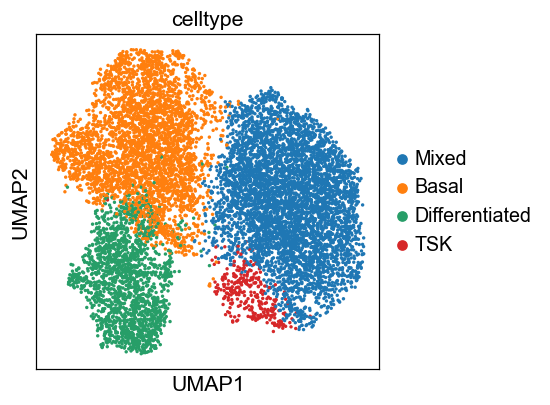

In [ ]:
sc.pl.umap(adata, color = 'celltype', size = 20)

inferring a principal tree --> parameters used 
    40 principal points, sigma = 0.8, lambda = 700, metric = euclidean
    fitting:  24%|##4       | 12/50 [00:00<00:02, 13.68it/s]
    converged
    finished (0:00:00) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.


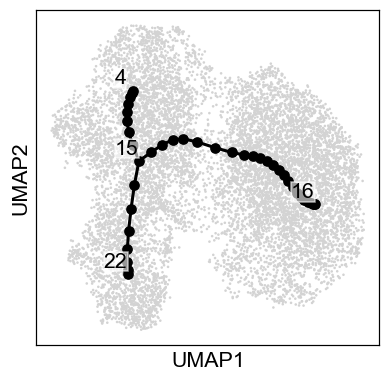

In [ ]:
# fit the principal tree. N=40/lambda=700/sigma=0.8 was chosen by a systematic sweep to give a
# clean 3-tip wishbone (Basal, Differentiated, Mixed arms + one convergence) with smooth monotone
# pseudotime (adjacent-cell smoothness ~0.96); the graph follows the manifold through the inter-lobe
# neck. No spurious side-branches, so no pruning is needed. Residual pile-up of pseudotime within the
# dense lobes is intrinsic to the two-lobe UMAP geometry (held across the whole parameter sweep).
scf.tl.tree(adata, method = 'ppt', Nodes = 40,
            ppt_lambda = 700, ppt_sigma = 0.8,
            use_rep = 'X_umap', seed = 1, plot = True, basis = 'umap')

In [ ]:
# root at the Basal tip (COL17A1+/TP63+ progenitor keratinocytes = developmental origin).
# Pick the Basal-annotated tip programmatically (data-driven, no hardcoded id).
B = adata.uns['graph']['B']; deg = (B > 0).sum(0)
F = adata.uns['graph']['F']; Resp = adata.obsm['X_R']
tips  = np.where(deg == 1)[0]; forks = np.where(deg > 2)[0]
ct = adata.obs['celltype'].values
node_ct = np.array([pd.Series(Resp[:, n]).groupby(ct).sum().idxmax() for n in range(F.shape[1])])
root_tip = int([t for t in tips if node_ct[t] == 'Basal'][0])
print('tips', [(int(t), node_ct[t]) for t in tips])
print('forks', [(int(f), node_ct[f]) for f in forks])
print('root (Basal tip) =', root_tip)
scf.tl.root(adata, root_tip)

tips [(4, np.str_('Basal')), (16, np.str_('Mixed')), (22, np.str_('Differentiated'))]
forks [(15, np.str_('Basal'))]
root (Basal tip) = 4
node 4 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.


<ipython-input-24-7a0abea0940e>:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  node_ct = np.array([pd.Series(Resp[:, n]).groupby(ct).sum().idxmax() for n in range(F.shape[1])])
<ipython-input-24-7a0abea0940e>:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  node_ct = np.array([pd.Series(Resp[:, n]).groupby(ct).sum().idxmax() for n in range(F.shape[1])])
<ipython-input-24-7a0abea0940e>:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence t

In [ ]:
scf.tl.pseudotime(adata, n_jobs = 4, seed = 1)

projecting cells onto the principal graph
    finished (0:00:06) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


pseudotime smoothness r = 0.961


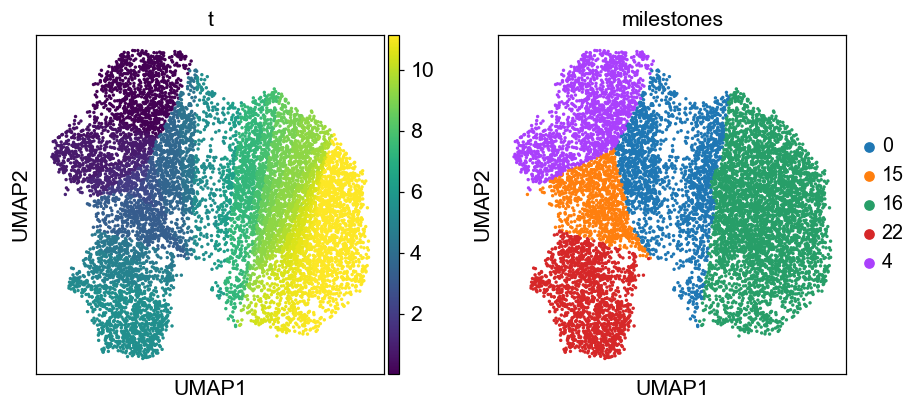

In [ ]:
# pseudotime smoothness check (adjacent-kNN correlation of t; ~1 = smooth monotone gradient)
A = (adata.obsp['connectivities'] > 0).astype(int); ii, jj = A.nonzero()
print('pseudotime smoothness r =', round(float(np.corrcoef(adata.obs['t'].values[ii],
                                                            adata.obs['t'].values[jj])[0, 1]), 3))
sc.pl.umap(adata, color = ['t', 'milestones'], size = 20)

In [ ]:
# Gate-3 test population = the BASAL root compartment (the fate-decision zone where the two
# competing programs are co-active before commitment). Stored as adata.obs['hub'] for 04-05.
adata.obs['hub'] = (adata.obs['celltype'] == 'Basal').values
print('hub (Basal) cells =', int(adata.obs['hub'].sum()))

hub (Basal) cells = 3524


milestones: ['Basal', 'Fork', 'Mixed', 'Differentiated', 'Basal_root']


/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


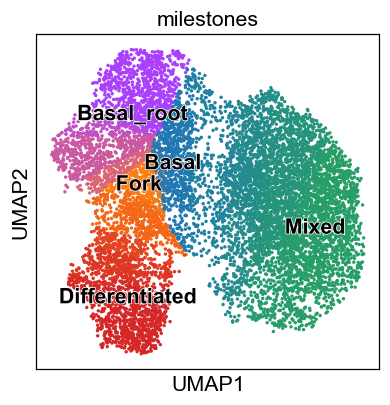

In [ ]:
# name milestones by biology, keeping labels unique. Root = Basal tip; the fork opens into a
# Differentiated arm and a Mixed (Crest-high) terminal arm.
cats = list(adata.obs['milestones'].cat.categories); fork_ids = set(int(x) for x in forks)
base = {}
for n in cats:
    ni = int(n)
    base[n] = ('Basal_root' if ni == root_tip else 'Fork' if ni in fork_ids else str(node_ct[ni]))
cnt = {}; uniq = {}
for n in cats:
    b = base[n]; tot = list(base.values()).count(b); cnt[b] = cnt.get(b, 0) + 1
    uniq[n] = b if tot == 1 else f'{b}_{cnt[b]}'
scf.tl.rename_milestones(adata, new = uniq)
print('milestones:', list(adata.obs['milestones'].cat.categories))
scf.pl.milestones(adata, basis = 'umap', annotate = True, s = 20)

In [ ]:
adata.write(os.path.join(pth_in, 'manifold.h5ad'))
print('saved', os.path.join(pth_in, 'manifold.h5ad'))

saved ../../../../../../data/cancer/vertebrate/CCCA/Claude/Skin/Ji2020_Skin-9/manifold.h5ad


saved ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Skin/Ji2020_Skin-9/manifold.pdf


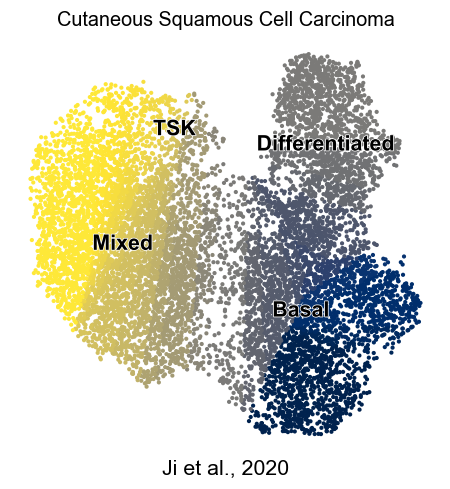

In [ ]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 't', cmap = 'cividis', size = 30, colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 30, alpha = 0, legend_loc = 'on data', legend_fontoutline = 1, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Cutaneous Squamous Cell Carcinoma', size = 13)
ax.text(.5, -.05, 'Ji et al., 2020', ha = 'center', transform = ax.transAxes)
fn = os.path.join(pth_out, 'manifold.pdf'); plt.savefig(fn, bbox_inches = 'tight'); print('saved', fn)